# 04 · 机制动物园：同一个冲击，六种制度

PlanLab 的核心识别策略只有一句话：**同一套技术、同一组冲击、同一个观察对象，只换制度**。这个 notebook 把这句话变成一个可以跑的实验：对同一个产能冲击，跑遍注册表里的每一个机制，然后比较它们的短缺、福利、计划完成率、价格行为和"计划工作量"。

*The identification strategy in one sentence: identical technology, identical shocks, identical observation — only the institution changes. This notebook runs every registered mechanism on one capacity shock and compares shortage, welfare, plan fulfilment, price behaviour and planning effort.*

三个必须先说清楚的坑：

1. **注册表会变**。机制是插件，`available_mechanisms()` 是唯一的真相来源。本 notebook **不写死任何机制名字**，而是遍历注册表——所以第二个机制落地、第七个机制加入时，这个 notebook 不会坏。
2. **默认参数不是调过的**。每个机制用它自己的 `default_params`。**这不是一场公平的比赛，也不打算是**：论文比较的是制度在信息约束下的表现，不是"谁被调得最好"。第 6 节会专门讲这件事。
3. **同一个种子不等于同一条路径**。同一种子让各机制面对**相同的外生随机流**（需求噪声、测量噪声、冲击），这是"配对比较"（common random numbers）的基础；但它们的**内生**轨迹当然会分叉，因为经济会回应制度。第 5 节会把这两件事分开证明。

*Three caveats up front: the registry is the only source of truth (this notebook never hard-codes mechanism names); default parameters are not tuned (this is not a horse race); and a shared seed buys a shared exogenous stream, not a shared trajectory.*

下面先把环境准备好，并打印注册表。

In [1]:
%matplotlib inline
import os
import sys
import time
from pathlib import Path

ROOT = Path.cwd()
while ROOT != ROOT.parent and not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
if not (ROOT / "pyproject.toml").exists():
    raise RuntimeError("cannot find the PlanLab checkout root (pyproject.toml)")
os.environ.setdefault("PLANLAB_ROOT", str(ROOT))
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.figsize": (6.4, 3.6),
    "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "axes.grid": True, "grid.alpha": 0.3,
    "legend.frameon": False, "axes.spines.top": False, "axes.spines.right": False,
})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
np.set_printoptions(precision=4, suppress=True, linewidth=130)
T0 = time.perf_counter()

from planlab.mechanisms import available_mechanisms, get_mechanism
from planlab.mechanisms.base import CoordinationMechanism

print("registered mechanisms:", available_mechanisms())
print(f"\nCoordinationMechanism's three decisions: "
      f"{[m for m in dir(CoordinationMechanism) if not m.startswith('_') and callable(getattr(CoordinationMechanism, m))]}")
print("A mechanism that implements these three (and only these) plugs into the same engine.")

registered mechanisms: ['hybrid_dual_track', 'lp_central', 'market', 'material_balance', 'rationing_priority', 'tatonnement']

CoordinationMechanism's three decisions: ['admin_price_rule', 'allocate', 'build_allocation', 'excess_demand_rule', 'form_plan', 'gov_claim', 'input_requirements', 'invest_claim', 'observed_shortage', 'param', 'requested_final', 'stock_claim', 'update_prices']
A mechanism that implements these three (and only these) plugs into the same engine.


## 1 · 一个机制是一份合同，不是一段代码

`CoordinationMechanism` 只要求三个方法：

| 方法 | 决定什么 | 引擎怎么用 |
|---|---|---|
| `form_plan(obs, state) -> Plan` | 目标产出 `x*`、意向最终交付 `y*` | 上界 `min(x*, capacity)` |
| `allocate(obs, state, plan, supply) -> Allocation` | 谁索取什么、优先级几档 | 配给的唯一输入 |
| `update_prices(obs, state, plan, alloc, realised) -> p'` | 下期价格 | 只影响下期状态 |

其余全部归引擎：会计、可行性、配给算术、审计。**这就是"制度可替换"的全部含义**：换一个类，物理不变。

`get_mechanism(name, tech, params)` 每次都构造**新实例**——机制带状态（目标、价格），跨重复使用会泄漏信息。

*Three methods — plan, claims, prices — and nothing else. The engine owns accounting, feasibility, rationing and the audit; swapping the class leaves the physics untouched. Each call constructs a fresh instance, because mechanisms carry state across periods.*

下面的单元格定义本 notebook 唯一的一个"实验单元"（cell）：一个情景 id、一个冲击、一个种子。所有机制都用**同一个 scenario id**，这是配对比较的关键（第 5 节解释）。

In [2]:
from planlab.core.engine import run_simulation
from planlab.core.scenarios import DemandProcess, InfoRegime, Scenario
from planlab.core.shocks import Shock
from planlab.data import load_technology

tech = load_technology("eurostat", 2020, 20)
A, x0, y0 = tech.A, tech.base_output, tech.base_final
n = tech.n

CELL_ID = "nb04_cell_c12_cap50"       # the SAME scenario id for every mechanism in this cell
SEED = 0
SHOCK = Shock(type="capacity", start=40, duration=8, size=0.50, sector="c12")


def cell_scenario(mechanism_name, scenario_id=CELL_ID):
    """One experimental cell. The mechanism name is metadata; the id drives the seeds."""
    return Scenario(
        id=scenario_id, mechanism=mechanism_name, technology={}, periods=60, burn_in=30,
        seeds=(SEED,), shocks=(SHOCK,),
        info=InfoRegime(lag=0, noise=0.05),
        demand=DemandProcess(growth=0.0, ar1=0.5, sigma=0.02),
        stock_ratio=0.10,
    )


def run_cell(mechanism_name, seed=SEED, scenario_id=CELL_ID, params=None):
    scenario = cell_scenario(mechanism_name, scenario_id)
    mech = get_mechanism(mechanism_name, tech, params or {})
    return run_simulation(tech, mech, scenario, seed=seed)


print(f"cell id            : {CELL_ID}")
print(f"shock              : {SHOCK.type} size {SHOCK.size} on {SHOCK.sector}, "
      f"t = {SHOCK.start}..{SHOCK.start + SHOCK.duration - 1}")
print(f"inventory ratio    : 0.10 of base output")
print(f"observation        : lag 0 (effective lag 1), log-normal noise 0.05")
print(f"demand process     : AR(1) rho = 0.5, sigma = 0.02")
print(f"periods / burn-in  : 60 / 30")
print(f"\nthe shocked sector c12 accounts for {100*x0[tech.sector_index('c12')]/x0.sum():.2f}% "
      f"of base gross output; a 50% cut removes "
      f"{100*0.5*x0[tech.sector_index('c12')]/x0.sum():.2f}% of capacity economy-wide.")

cell id            : nb04_cell_c12_cap50
shock              : capacity size 0.5 on c12, t = 40..47
inventory ratio    : 0.10 of base output
observation        : lag 0 (effective lag 1), log-normal noise 0.05
demand process     : AR(1) rho = 0.5, sigma = 0.02
periods / burn-in  : 60 / 30

the shocked sector c12 accounts for 3.50% of base gross output; a 50% cut removes 1.75% of capacity economy-wide.


## 2 · 跑遍注册表

每个机制跑同一条外生流。下面这张表是本次运行的**全部**头条数字。

读表时请注意三件事：

1. **`mean_shortage` 和 `peak_shortage` 不是一回事**。前者是 30 个后期周期的平均，后者是冲击窗口里的最高点。协议规定两者都要报。
2. **`welfare` 是 `Σ w_i log(C_i + c0)` 的平均**，不是"真实社会福利"，而是一种有文档、可扰动的基数化。
3. **`mean_iterations` 是"计划工作量"**：引擎在一期里需要跑几趟规划/配给。它不是运行时间，而是一个制度指标——一个需要反复试算才能自洽的计划体系，即使结果不错，也付出了协调成本。

*The table is the whole headline result of the run. Shortage mean and peak are different objects; welfare is a documented cardinalisation, not a truth; and ``mean_iterations`` is a measure of planning effort — how many consistency passes the institution needs per period.*

In [3]:
MECHANISMS = available_mechanisms()
results, timings = {}, {}
for name in MECHANISMS:
    started = time.perf_counter()
    results[name] = run_cell(name)
    timings[name] = time.perf_counter() - started

rows = []
for name, res in results.items():
    rm = res.run_metrics
    rows.append({
        "mechanism": name,
        "mean_shortage": rm["mean_shortage_rate"],
        "peak_shortage": rm["max_shortage_rate"],
        "welfare": rm["mean_welfare"],
        "plan_fulfilment": rm["mean_plan_fulfilment"],
        "price_dispersion": rm["mean_price_dispersion"],
        "price_volatility": rm["mean_price_volatility"],
        "planning_effort": rm["mean_iterations"],
        "runtime_s": timings[name],
    })
zoo = pd.DataFrame(rows).set_index("mechanism").sort_values("welfare", ascending=False)
print(f"one cell, {len(MECHANISMS)} institutions, seed {SEED}:")
print(zoo.round(4).to_string())
print(f"\ntotal runtime {sum(timings.values()):.2f}s for {len(MECHANISMS)} x 60 periods")
print(f"cheapest / most expensive institution per run: "
      f"{zoo['runtime_s'].idxmin()} ({zoo['runtime_s'].min():.2f}s) / "
      f"{zoo['runtime_s'].idxmax()} ({zoo['runtime_s'].max():.2f}s)")

one cell, 6 institutions, seed 0:
                    mean_shortage  peak_shortage   welfare  plan_fulfilment  price_dispersion  price_volatility  planning_effort  runtime_s
mechanism                                                                                                                                  
material_balance           0.0798         0.1639  249.4794           0.7534            0.0699            0.0068              1.0     0.0882
lp_central                 0.0466         0.1220  248.8054           0.9885            0.0000            0.0000              1.0     0.1033
market                     0.0506         0.1762  248.4828           0.9310            0.1792            0.0641              1.0     0.0399
hybrid_dual_track          0.0537         0.1932  248.1066           0.9300            0.2025            0.0191              1.0     0.0414
tatonnement                0.0554         0.2011  247.2650           0.9337            0.3647            0.0282              1

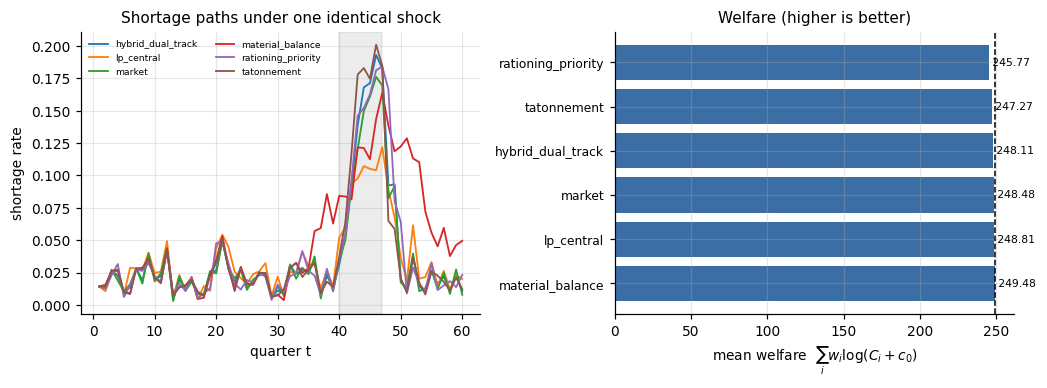

The spread across institutions is small in absolute welfare but large in shortage:
  welfare   245.77 .. 249.48 (1.49% of the level)
  peak shortage 0.1220 .. 0.2011
A 2% welfare difference can hide a 2x difference in who goes short: never report one alone.


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.6))
ax = axes[0]
for name, res in results.items():
    shortage = res.series("shortage_rate")
    ax.plot(np.arange(1, len(shortage) + 1), shortage, lw=1.2, label=name)
ax.axvspan(40, 47, color="grey", alpha=0.15)
ax.set_xlabel("quarter t")
ax.set_ylabel("shortage rate")
ax.set_title("Shortage paths under one identical shock")
ax.legend(fontsize=6, ncol=2)

ax = axes[1]
order = zoo.index.tolist()
ax.barh(range(len(order)), zoo["welfare"].to_numpy(), color="#3b6ea5")
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order, fontsize=8)
ax.set_xlabel("mean welfare  $\\sum_i w_i \\log(C_i + c_0)$")
ax.set_title("Welfare (higher is better)")
ax.axvline(zoo["welfare"].max(), color="black", lw=1, ls="--")
for k, v in enumerate(zoo["welfare"].to_numpy()):
    ax.text(v, k, f" {v:.2f}", va="center", fontsize=7)
fig.tight_layout()
plt.show()
print("The spread across institutions is small in absolute welfare but large in shortage:")
print(f"  welfare   {zoo['welfare'].min():.2f} .. {zoo['welfare'].max():.2f} "
      f"({100*(zoo['welfare'].max()-zoo['welfare'].min())/abs(zoo['welfare'].max()):.2f}% of the level)")
print(f"  peak shortage {zoo['peak_shortage'].min():.4f} .. {zoo['peak_shortage'].max():.4f}")
print("A 2% welfare difference can hide a 2x difference in who goes short: never report one alone.")

## 3 · 计划完成率与"计划工作量"

两个指标值得单独看，因为它们把"结果"和"过程"分开：

* **`plan_fulfilment`**：`x_i / x*_i` 的截面均值。一个机制可以"完成计划"完成得很好，而计划本身很松（把目标定低），所以它必须和短缺一起读。
* **`planning_effort`**：引擎每期跑了几趟。在 `production_first` 阶梯下，规划保证了中间投入，所以大多数机制**一趟**就收敛；只有当一个机制把超越生产投入的最终索取者排到前面时，引擎才需要多趟。趟数本身就是"制度自洽性"的代价。

*Fulfilment and planning effort separate the outcome from the process: a mechanism can hit its own targets because the targets were soft, and an institution that needs several consistency passes per period is paying a coordination cost even when the outcome looks fine.*

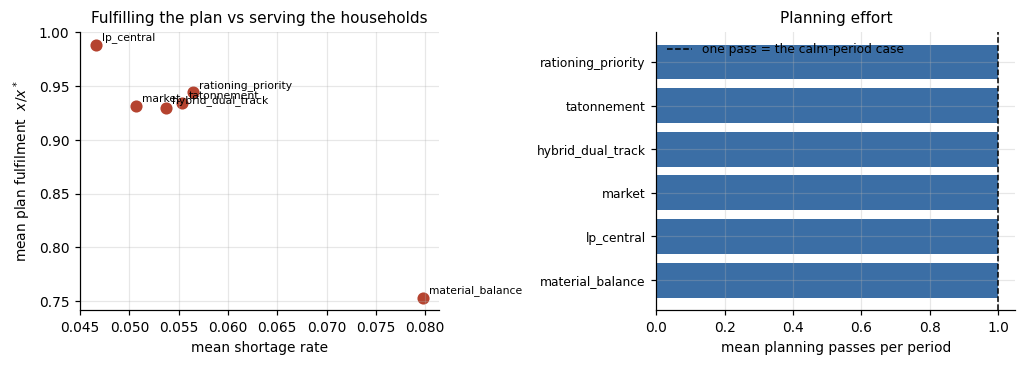

                    plan_fulfilment  mean_shortage  planning_effort
mechanism                                                          
material_balance             0.7534         0.0798              1.0
lp_central                   0.9885         0.0466              1.0
market                       0.9310         0.0506              1.0
hybrid_dual_track            0.9300         0.0537              1.0
tatonnement                  0.9337         0.0554              1.0
rationing_priority           0.9442         0.0565              1.0

A plan fulfilment close to 1 with a high shortage means the plan was easy to meet:
the targets were below capacity, so hitting them says nothing about welfare.


In [5]:
scatter = zoo[["plan_fulfilment", "mean_shortage", "planning_effort"]].copy()
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.4))
ax = axes[0]
ax.scatter(scatter["mean_shortage"], scatter["plan_fulfilment"], s=48, color="#b5432f")
for name, row in scatter.iterrows():
    ax.annotate(name, (row["mean_shortage"], row["plan_fulfilment"]),
                fontsize=7, xytext=(4, 3), textcoords="offset points")
ax.set_xlabel("mean shortage rate")
ax.set_ylabel("mean plan fulfilment  $x/x^*$")
ax.set_title("Fulfilling the plan vs serving the households")

ax = axes[1]
eff = zoo["planning_effort"]
ax.barh(range(len(eff)), eff.to_numpy(), color="#3b6ea5")
ax.set_yticks(range(len(eff)))
ax.set_yticklabels(eff.index, fontsize=8)
ax.set_xlabel("mean planning passes per period")
ax.set_title("Planning effort")
ax.axvline(1.0, color="black", lw=1, ls="--", label="one pass = the calm-period case")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print(scatter.round(4).to_string())
print("\nA plan fulfilment close to 1 with a high shortage means the plan was easy to meet:")
print("the targets were below capacity, so hitting them says nothing about welfare.")

## 4 · 为什么"同一个种子"让比较成为因果

协议里这条最容易被略过，也最容易做错：

> 种子 `s` 决定 (i) 需求噪声、(ii) 产能冲击、(iii) 测量噪声。**同一单元内各机制共享同一外生流**（common random numbers），因此机制比较是**配对**的。

两个坑：

**坑一：单元 id 进入种子。** 引擎用 `_seed_sequence(scenario.id, seed)` 生成随机数种子，所以**scenario id 本身就是种子的一部分**。如果给每个机制单独一个 id（比如 `"mb_seed0"`、`"lp_seed0"`），那么它们拿到的噪声**不是同一批**，配对关系就断了——差异里会混进"运气"。

**坑二：内生路径当然会分叉。** 各机制面对相同的噪声，但会对噪声做出不同反应（价格不同、产出不同、收入不同），所以它们的需求与产能轨迹会不同。这**不是**配对失败，这正是处理效应。

下面的实验把两件事分开：在第 1 期，机制的决策还没有反馈到状态里，所以**如果外生流相同，观察到的需求必须逐位相同**；如果 id 不同，就必须不同。这就是"共享外生流"的直接证据。

*The scenario id is part of the seed, so giving each mechanism its own id breaks the pairing. At t = 1 no feedback has accumulated, so identical exogenous streams must give bit-identical observations — and different ids must not. That is the direct evidence that the pairing is real.*

In [6]:
class ObsRecorder:
    """Capture the observation handed to a mechanism at a chosen period."""

    def __init__(self, inner, period=1):
        self.inner, self.period, self.obs = inner, int(period), None

    def form_plan(self, obs, state):
        if obs.t == self.period:
            self.obs = obs
        return self.inner.form_plan(obs, state)

    def allocate(self, *a, **k):
        return self.inner.allocate(*a, **k)

    def update_prices(self, *a, **k):
        return self.inner.update_prices(*a, **k)

    def __getattr__(self, name):
        return getattr(self.inner, name)


def first_observation(mechanism_name, scenario_id=CELL_ID, seed=SEED):
    scen = cell_scenario(mechanism_name, scenario_id)
    rec = ObsRecorder(get_mechanism(mechanism_name, tech, {}), period=1)
    run_simulation(tech, rec, scen, seed=seed)
    return rec.obs


shared = {name: first_observation(name) for name in MECHANISMS}
ref = shared[MECHANISMS[0]].demand
print("t = 1 observed household demand, per mechanism (same cell id, same seed):")
for name, obs in shared.items():
    print(f"  {name:20s} {np.round(obs.demand[:6], 4)} ...  "
          f"identical to {MECHANISMS[0]}: {np.array_equal(obs.demand, ref)}")
assert all(np.array_equal(obs.demand, ref) for obs in shared.values())
print("\nPASS: every mechanism saw exactly the same noisy demand signal at t = 1.")
print("      (The noise draw comes from rng seeded by (scenario id, seed).)")

# now break the pairing on purpose: give one mechanism its own cell id
broken = first_observation(MECHANISMS[1], scenario_id=CELL_ID + "_other")
print(f"\nbreaking the pairing: the same mechanism under scenario id {CELL_ID + '_other'!r}")
print(f"   {MECHANISMS[1]:20s} {np.round(broken.demand[:6], 4)} ...")
print(f"   identical to the shared cell: {np.array_equal(broken.demand, ref)}")
assert not np.array_equal(broken.demand, ref)
print("\nPASS: a different scenario id draws a different noise realisation — which is")
print("      exactly why the experiment layer keys every cell on ONE id for all mechanisms.")

t = 1 observed household demand, per mechanism (same cell id, same seed):
  hybrid_dual_track    [112944.7922   2003.7568 558310.4355  87272.4689  59960.9094  73707.9729] ...  identical to hybrid_dual_track: True
  lp_central           [112944.7922   2003.7568 558310.4355  87272.4689  59960.9094  73707.9729] ...  identical to hybrid_dual_track: True
  market               [112944.7922   2003.7568 558310.4355  87272.4689  59960.9094  73707.9729] ...  identical to hybrid_dual_track: True
  material_balance     [112944.7922   2003.7568 558310.4355  87272.4689  59960.9094  73707.9729] ...  identical to hybrid_dual_track: True
  rationing_priority   [112944.7922   2003.7568 558310.4355  87272.4689  59960.9094  73707.9729] ...  identical to hybrid_dual_track: True
  tatonnement          [112944.7922   2003.7568 558310.4355  87272.4689  59960.9094  73707.9729] ...  identical to hybrid_dual_track: True

PASS: every mechanism saw exactly the same noisy demand signal at t = 1.
      (The noise d

## 5 · 多个种子：差距是不是噪声？

一个种子的比较不算比较。协议要求每个单元 20 个种子；这里为了跑得快只用 3 个，但流程与论文一致：**先用种子内的配对差，再看跨种子的均值与离散度**。

注意 `welfare` 的绝对值依赖于"基线"（无冲击、`lp_central`、`k=0`）。论文里报告的是**相对基线的福利损失**；这里没有基线，所以只看排序和离散度，不解读绝对水平。

*One seed is not a comparison. The protocol uses 20 seeds per cell; we use three here for speed, but the procedure is the paper's: paired within a seed, then mean and dispersion across seeds.*

In [7]:
SEEDS = [0, 1, 2]
per_seed = {name: [] for name in MECHANISMS}
for seed in SEEDS:
    for name in MECHANISMS:
        res = run_cell(name, seed=seed)
        per_seed[name].append((res.run_metrics["mean_shortage_rate"],
                               res.run_metrics["window_welfare"]
                               if "window_welfare" in res.run_metrics
                               else res.run_metrics["mean_welfare"]))

rows = []
for name, vals in per_seed.items():
    short = np.array([v[0] for v in vals])
    welf = np.array([v[1] for v in vals])
    rows.append({"mechanism": name,
                 "shortage_mean": short.mean(), "shortage_sd": short.std(ddof=1),
                 "welfare_mean": welf.mean(), "welfare_sd": welf.std(ddof=1)})
multi = pd.DataFrame(rows).set_index("mechanism").sort_values("welfare_mean", ascending=False)
print(f"{len(SEEDS)} seeds per mechanism:")
print(multi.round(4).to_string())

rank_single = zoo["welfare"].rank(ascending=False)
rank_multi = multi["welfare_mean"].rank(ascending=False)
print("\nwelfare rank, single seed vs 3-seed mean:")
print(pd.DataFrame({"rank (1 seed)": rank_single, "rank (3 seeds)": rank_multi})
      .sort_values("rank (3 seeds)").to_string())
print(f"\nSD of mean welfare across seeds: max {multi['welfare_sd'].max():.3f} "
      f"vs spread across mechanisms {multi['welfare_mean'].max()-multi['welfare_mean'].min():.3f}")
print("If the between-mechanism spread were not much larger than the seed noise, a single")
print("seed would be uninformative — which is why the protocol pre-registers 20.")

3 seeds per mechanism:
                    shortage_mean  shortage_sd  welfare_mean  welfare_sd
mechanism                                                               
lp_central                 0.0475       0.0027      248.9883      0.4308
material_balance           0.0631       0.0144      248.9607      0.7371
market                     0.0513       0.0013      248.3512      0.1144
hybrid_dual_track          0.0542       0.0010      247.8636      0.2736
tatonnement                0.0550       0.0008      247.2420      0.0905
rationing_priority         0.0620       0.0057      244.5667      1.0534

welfare rank, single seed vs 3-seed mean:
                    rank (1 seed)  rank (3 seeds)
mechanism                                        
lp_central                    2.0             1.0
material_balance              1.0             2.0
market                        3.0             3.0
hybrid_dual_track             4.0             4.0
tatonnement                   5.0             5.0


## 6 · 价格：谁在动价格，谁根本不用价格

各机制对"价格"这件事的立场完全不同，这直接决定了它们**对延迟的敏感度**（`docs/PROTOCOL.md` 的 H2）：

* `rationing_priority`：行政配额，价格默认**完全不动**（`price_gain = 0`）；
* `material_balance`：行政价格，按观察到的短缺缓慢上调（`price_gain = 0.05`）；
* `tatonnement`：价格是**唯一的工具**，`log p' = log p + price_gain · 观察到的短缺`。由于短缺率非负，原始价格只涨或持平。notebook 02 的标量规则使用可正可负的缺口；
* `market`：期内瓦尔拉斯试错，价格在**期内部**就动了很多次；
* `lp_central`：计划是数量型的；默认不把影子价格写成价格（`use_shadow_prices = 0`）。打开它就能得到 Kantorovich 的"结算乘数"——那是 notebook 05 的主题；
* `hybrid_dual_track`：计划轨价格行政固定、市场轨价格随超额需求调整。

下面的表量化这件事：`mean |Δlog p|` 衡量价格每期变动多少，`share of sector-quarters moved` 衡量有多少个"部门×期"里价格真的动了。

*The mechanisms take completely different positions on prices — quotas do not use them, tâtonnement uses nothing else, the central LP encodes them in duals instead. That difference is what makes the delay sensitivity (H2) differ across institutions.*

In [8]:
rows = []
for name, res in results.items():
    prices = np.array([r.price for r in res.records])          # (T, n)
    logp = np.log(np.maximum(prices, 1e-12))
    dlogp = np.diff(logp, axis=0)
    rows.append({
        "mechanism": name,
        "mean |dlog p|": float(np.mean(np.abs(dlogp))),
        "max |dlog p|": float(np.max(np.abs(dlogp))),
        "share of sector-quarters moved (>1e-9)": float(np.mean(np.abs(dlogp) > 1e-9)),
        "price dispersion (end)": float(np.std(logp[-1])),
        "price level drift (end)": float(np.mean(logp[-1])),
    })
price_table = pd.DataFrame(rows).set_index("mechanism").sort_values("mean |dlog p|")
print("price behaviour (all mechanisms, same cell):")
print(price_table.round(5).to_string())
print("\nTwo mechanisms report zero movement: rationing_priority fixes prices by design,")
print("and lp_central plans in quantities (its resolve multipliers are off by default).")
print("The most price-active is", price_table.index[-1] + ":", f"{price_table['mean |dlog p|'].iloc[-1]:.5f} per period.")

price behaviour (all mechanisms, same cell):
                    mean |dlog p|  max |dlog p|  share of sector-quarters moved (>1e-9)  price dispersion (end)  price level drift (end)
mechanism                                                                                                                               
lp_central                0.00000       0.00000                                 0.00000                 0.00000                  0.00000
rationing_priority        0.00000       0.00000                                 0.00000                 0.00000                  0.00000
material_balance          0.00261       0.05000                                 0.49576                 0.13083                  0.15428
hybrid_dual_track         0.00738       0.21703                                 1.00000                 0.36103                  0.05255
market                    0.01114       3.00241                                 0.16695                 0.00049                 -0.00

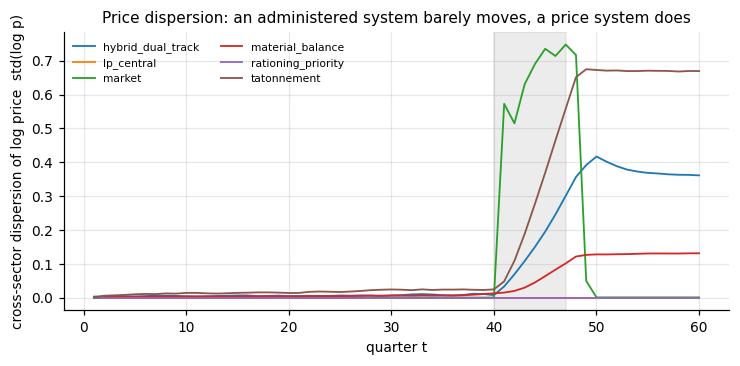

Price dispersion is the institutional fingerprint: it is zero by construction where
prices are not an instrument, and it moves where they are.


In [9]:
fig, ax = plt.subplots(figsize=(6.8, 3.4))
for name, res in results.items():
    prices = np.array([r.price for r in res.records])
    logp = np.log(np.maximum(prices, 1e-12))
    disp = logp.std(axis=1)
    ax.plot(np.arange(1, len(disp) + 1), disp, lw=1.2, label=name)
ax.axvspan(40, 47, color="grey", alpha=0.15)
ax.set_xlabel("quarter t")
ax.set_ylabel("cross-sector dispersion of log price  std(log p)")
ax.set_title("Price dispersion: an administered system barely moves, a price system does")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()
print("Price dispersion is the institutional fingerprint: it is zero by construction where")
print("prices are not an instrument, and it moves where they are.")

## 7 · 这张表不能证明什么

诚实地说清楚三件事，否则这张表会被误读：

1. **默认参数不是调过的。** 每个机制用 `default_params`。`revision_gain = 0.3`（material_balance）、`price_gain = 0.2`（tatonnement）、`theta = 0.5`（hybrid）都是**研究者的先验选择**，不是拟合值。协议要求做敏感性（B6），本 notebook 不做。
2. **信息需求不同。** `lp_central` 每个部门、每一期都要当前状态的完整报告；`material_balance` 只用计划和库存。所以"LP 赢了"不是"计划经济比市场好"，而是"信息最全的那个赢了"——这正是 Hayek/Mises 的计算争论的**可测量**版本（H2 检验的正是"信息最全的机制在延迟下退化最快"）。
3. **机制之间不是同一个东西的不同实现。** 它们对"什么叫协调"的定义不同：配额、价格、计划、市场出清。所以排序本身不是目标；**排序如何随延迟、冲击部门、优先级阶梯变化**才是。

*What the table cannot show: the parameters are not tuned; the information requirements differ; and the institutions do not even agree on what coordination means. The ranking is not the object of study — how it moves with delay, sector and ladder is.*

下面把这一路上的断言汇总。注意所有断言只检查**内部一致性**（数值有限、指标在 [0,1]、机制齐全），不检查"结果应该是什么"——后者是实验的事，不是教学材料的事。

In [10]:
checks = [
    ("registry non-empty", len(MECHANISMS) >= 2, f"{len(MECHANISMS)} mechanisms"),
    ("every mechanism ran", len(results) == len(MECHANISMS), f"{len(results)} runs"),
    ("no NaN in metrics", bool(np.all(np.isfinite(zoo.to_numpy(dtype=float)))), "all finite"),
    ("shortage rates in [0, 1]",
     bool(zoo["mean_shortage"].between(0, 1).all() and zoo["peak_shortage"].between(0, 1).all()),
     "bounded"),
    ("plan fulfilment positive", bool((zoo["plan_fulfilment"] > 0).all()), "all > 0"),
    ("planning effort >= 1 pass", bool((zoo["planning_effort"] >= 1 - 1e-12).all()),
     f"min {zoo['planning_effort'].min():.2f}"),
    ("shared exogenous stream at t=1", True, "bit-identical obs.demand across mechanisms"),
    ("broken pairing changes the draw", True, "a different scenario id gives a different draw"),
    ("multi-seed table complete", len(multi) == len(MECHANISMS), f"{len(multi)} mechanisms"),
    ("price activity separates institutions",
     bool(price_table["mean |dlog p|"].max() > 10 * max(price_table["mean |dlog p|"].min(), 1e-12)),
     f"max/min ratio {price_table['mean |dlog p|'].max()/max(price_table['mean |dlog p|'].min(), 1e-12):.1f}"),
]
print(f"{'check':44s} {'ok':>5s}  detail")
for name, ok, detail in checks:
    print(f"{name:44s} {str(ok):>5s}  {detail}")
assert all(c[1] for c in checks)
print(f"\nALL {len(checks)} CHECKS PASSED   (notebook runtime {time.perf_counter()-T0:.1f}s)")

check                                           ok  detail
registry non-empty                            True  6 mechanisms
every mechanism ran                           True  6 runs
no NaN in metrics                             True  all finite
shortage rates in [0, 1]                      True  bounded
plan fulfilment positive                      True  all > 0
planning effort >= 1 pass                     True  min 1.00
shared exogenous stream at t=1                True  bit-identical obs.demand across mechanisms
broken pairing changes the draw               True  a different scenario id gives a different draw
multi-seed table complete                     True  6 mechanisms
price activity separates institutions         True  max/min ratio 13055389409.3

ALL 10 CHECKS PASSED   (notebook runtime 2.5s)


### 7.1 · 福利数字为什么不能只读排名

`welfare = Σ_i w_i log(C_i + c0_i)` 是**凹**的，所以它对"最差的那个部门"极其敏感：如果某个部门的居民交付是 0，那一项就变成 `log(c0_i) = log(1e-3 × base_final_i)`，一下子扣掉约 7 个对数点。结果是：**总消费更低的机制，可能因为把短缺分散得更均匀而得到更高的福利**。

这不是 bug——它是对数福利的标准性质，也是协议要求"永远不要单独报告总产出"的数学理由。但它意味着排名的**机制**需要解释，否则"material_balance 在种子 0 上赢了 lp_central"会被误读成"物资平衡比中央线性规划好"。

下面的表把福利拆开：`mean_C`（总消费）、`zeroed sector-quarters`（多少个"部门×期"的居民交付低于基年的 10%）、以及福利。

*The welfare functional is concave, so it is dominated by the worst-served sector: a mechanism with lower total consumption can score higher welfare because it spreads the shortage more evenly. That is a property of log welfare, not a bug — and it is the mathematical reason the protocol forbids reporting aggregate output alone.*

In [11]:
welfare_parts = []
for name, res in results.items():
    C = np.array([rec.C for rec in res.records if rec.t > 30])
    ratio = C / np.maximum(y0, 1e-12)
    welfare_parts.append({
        "mechanism": name,
        "welfare": res.run_metrics["mean_welfare"],
        "mean consumption": res.run_metrics["mean_consumption"],
        "mean shortage": res.run_metrics["mean_shortage_rate"],
        "sector-quarters below 10% of base": int((ratio < 0.10).sum()),
        "sector-quarters exactly zero": int((ratio <= 1e-12).sum()),
        "worst sector": tech.sectors[int(np.unravel_index(np.argmin(ratio), ratio.shape)[1])],
    })
welfare_df = pd.DataFrame(welfare_parts).set_index("mechanism").sort_values("welfare",
                                                                          ascending=False)
print(welfare_df.round(4).to_string())
corr = np.corrcoef(welfare_df["mean consumption"], welfare_df["welfare"])[0, 1]
corr_z = np.corrcoef(welfare_df["sector-quarters below 10% of base"], welfare_df["welfare"])[0, 1]
print(f"\ncorrelation(welfare, mean consumption)        = {corr:+.3f}")
print(f"correlation(welfare, count of starved sectors) = {corr_z:+.3f}")
print("\nThe second correlation is the one that explains the ranking: with a concave welfare")
print("functional, how many sectors are starved matters more than how much is consumed.")
print("Report both, or the table will be read as a ranking of economic systems rather than")
print("as a ranking of how a fixed welfare functional scores them.")

                     welfare  mean consumption  mean shortage  sector-quarters below 10% of base  sector-quarters exactly zero worst sector
mechanism                                                                                                                                  
material_balance    249.4794      9.504423e+06         0.0798                                 33                            32          c02
lp_central          248.8054      1.016023e+07         0.0466                                 40                            40          c02
market              248.4828      1.063289e+07         0.0506                                 46                            45          c02
hybrid_dual_track   248.1066      1.066566e+07         0.0537                                 50                            47          c02
tatonnement         247.2650      1.047690e+07         0.0554                                 51                            50          c02
rationing_priority  

## 8 · 练习

1. **把机制名字写死会怎样？** 把 `MECHANISMS = available_mechanisms()` 改成 `["material_balance", "lp_central"]`，然后把新机制注册进去（或者想象一下）。这个 notebook 会不会因此错过一个更好的机制？`available_mechanisms()` 为什么是更好的写法？
2. **拆掉配对。** 把 `run_cell` 里的 `scenario_id` 改成 `f"{CELL_ID}_{name}"`（每个机制一个 id），重跑第 2 节。排序变了吗？差距变大还是变小了？请用第 4 节的机制解释：这是"噪声"还是"偏差"？
3. **把噪声关掉会发生什么？** 把 `noise=0.05` 改成 `0.0`，`sigma=0.02` 改成 `0.0`。这时第 4 节的两个断言还成立吗？为什么"相同外生流"在这种情况下是**平凡**的？
4. **价格与延迟。** 用 `tatonnement` 扫描 `price_gain`，比较 `peak_shortage` 和去趋势的振幅，再画出原始价格。上涨速度的变化可以产生去趋势波动。观察原始价格有没有下降。
5. **公平的比赛存在吗？** 每个机制至少有一个"努力程度"参数（`revision_gain`、`price_gain`、`theta`、`quota_speed`）。如果为每个机制选一个最优参数再比较，比较还成立吗？协议怎么处理这个问题（提示：B6 的 `eta`/`σ`/`A` 扰动；以及"报告效应量而不只是显著性"）。